In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.tree import DecisionTreeClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score

import warnings
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Remove customer ID
df.drop("customerID", axis=1, inplace=True)

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Encode target variable
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Check dataset
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["Churn"].value_counts())

Dataset Shape: (7043, 20)

Missing Values:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [6]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [7]:
# First split: 80% train + validation, 20% test

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 60% train, 20% validation

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Percentage:",
      round(len(X_train)/len(df)*100, 2), "%")

print("Validation Percentage:",
      round(len(X_val)/len(df)*100, 2), "%")

print("Testing Percentage:",
      round(len(X_test)/len(df)*100, 2), "%")

Training Data: (4225, 19)
Validation Data: (1409, 19)
Testing Data: (1409, 19)

Training Percentage: 59.99 %
Validation Percentage: 20.01 %
Testing Percentage: 20.01 %


In [8]:
print("Original Churn Distribution:")
print(y.value_counts(normalize=True))

print("\nTraining Distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation Distribution:")
print(y_val.value_counts(normalize=True))

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True))

Original Churn Distribution:
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

Training Distribution:
Churn
0    0.734675
1    0.265325
Name: proportion, dtype: float64

Validation Distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64

Testing Distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [9]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

tree_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"),
     numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train_tree = tree_preprocessor.fit_transform(X_train)

X_val_tree = tree_preprocessor.transform(X_val)

In [10]:
depths = [1, 3, 5, 10, None]

train_accuracy = []
val_accuracy = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_tree, y_train)

    train_pred = model.predict(X_train_tree)
    val_pred = model.predict(X_val_tree)

    train_acc = accuracy_score(
        y_train, train_pred
    )

    validation_acc = accuracy_score(
        y_val, val_pred
    )

    train_accuracy.append(train_acc)
    val_accuracy.append(validation_acc)

    print("\nDepth:", depth)
    print("Train Accuracy:", round(train_acc, 4))
    print("Validation Accuracy:", round(validation_acc, 4))


Depth: 1
Train Accuracy: 0.7347
Validation Accuracy: 0.7346

Depth: 3
Train Accuracy: 0.7927
Validation Accuracy: 0.7906

Depth: 5
Train Accuracy: 0.8116
Validation Accuracy: 0.7871

Depth: 10
Train Accuracy: 0.8959
Validation Accuracy: 0.7672

Depth: None
Train Accuracy: 0.9983
Validation Accuracy: 0.7374


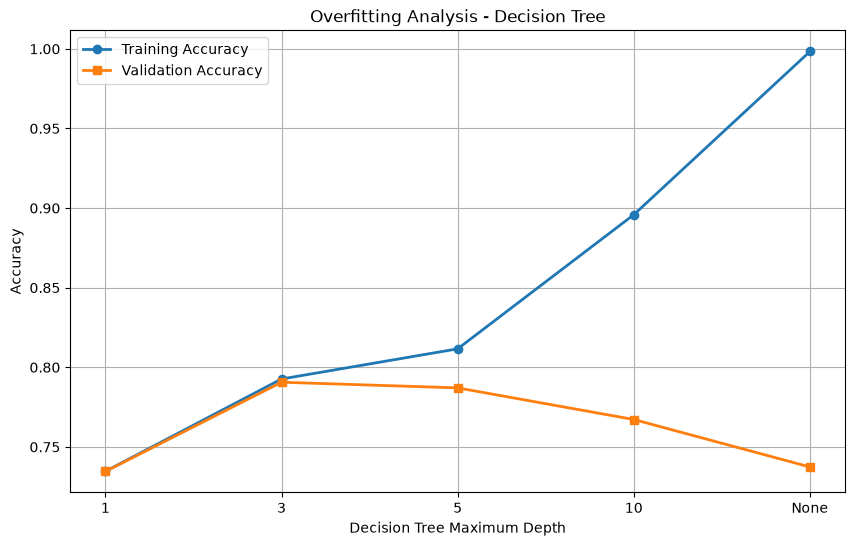

In [11]:
depth_labels = ["1", "3", "5", "10", "None"]

plt.figure(figsize=(10, 6))

plt.plot(
    depth_labels,
    train_accuracy,
    marker="o",
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    depth_labels,
    val_accuracy,
    marker="s",
    linewidth=2,
    label="Validation Accuracy"
)

plt.xlabel("Decision Tree Maximum Depth")
plt.ylabel("Accuracy")

plt.title("Overfitting Analysis - Decision Tree")

plt.legend()
plt.grid()
plt.show()

In [12]:
overfit_results = pd.DataFrame({
    "Max Depth": depth_labels,
    "Train Accuracy": train_accuracy,
    "Validation Accuracy": val_accuracy
})

overfit_results

,Max Depth,Train Accuracy,Validation Accuracy
0,1,0.734675,0.734564
1,3,0.792663,0.790632
2,5,0.811598,0.787083
3,10,0.895858,0.767211
4,None,0.998343,0.737402


In [13]:
logistic_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", logistic_preprocessor),

    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Cross Validation Scores:")
print(cv_scores)

print("\nMean Accuracy:",
      round(cv_scores.mean(), 4))

print("Standard Deviation:",
      round(cv_scores.std(), 4))

Cross Validation Scores:
[0.79289941 0.82130178 0.80828402 0.79408284 0.79526627]

Mean Accuracy: 0.8024
Standard Deviation: 0.011


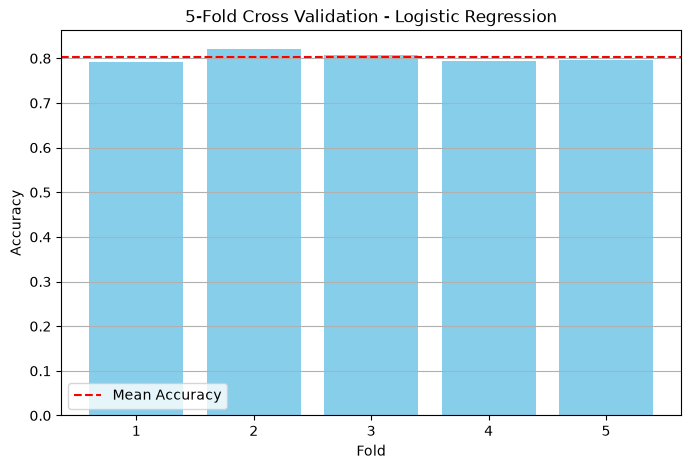

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    range(1, 6),
    cv_scores,
    color="skyblue"
)

plt.axhline(
    cv_scores.mean(),
    color="red",
    linestyle="--",
    label="Mean Accuracy"
)

plt.xlabel("Fold")
plt.ylabel("Accuracy")

plt.title("5-Fold Cross Validation - Logistic Regression")

plt.xticks(range(1, 6))
plt.legend()
plt.grid(axis="y")

plt.show()

In [16]:
# Use numeric columns for a simple leakage demonstration

X_numeric = X.select_dtypes(
    include=["int64", "float64"]
).copy()

# Fill missing values
X_numeric = X_numeric.fillna(
    X_numeric.median()
)

print(X_numeric.head())

   SeniorCitizen  tenure  MonthlyCharges  TotalCharges
0              0       1           29.85         29.85
1              0      34           56.95       1889.50
2              0       2           53.85        108.15
3              0      45           42.30       1840.75
4              0       2           70.70        151.65


In [17]:
# WRONG: Fit scaler on complete dataset

scaler_wrong = StandardScaler()

X_scaled_wrong = scaler_wrong.fit_transform(
    X_numeric
)

# Split after scaling

X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = train_test_split(
    X_scaled_wrong,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Incorrect scaling completed")

Incorrect scaling completed


In [18]:
# Split original data first

X_train_correct, X_test_correct, y_train_correct, y_test_correct = train_test_split(
    X_numeric,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit scaler only on training data

scaler_correct = StandardScaler()

X_train_correct_scaled = scaler_correct.fit_transform(
    X_train_correct
)

# Transform test data using training statistics

X_test_correct_scaled = scaler_correct.transform(
    X_test_correct
)

print("Correct scaling completed")

Correct scaling completed


In [19]:
print("Original Dataset Mean:")
print(X_numeric.mean())

print("\nIncorrect Scaler Mean:")
print(scaler_wrong.mean_)

print("\nCorrect Scaler Mean:")
print(scaler_correct.mean_)

Original Dataset Mean:
SeniorCitizen        0.162147
tenure              32.371149
MonthlyCharges      64.761692
TotalCharges      2281.916928
dtype: float64

Incorrect Scaler Mean:
[1.62146812e-01 3.23711487e+01 6.47616925e+01 2.28191693e+03]

Correct Scaler Mean:
[1.63294285e-01 3.24850905e+01 6.49299610e+01 2.30131903e+03]


Classification of Machine Learning Problems

1. Spam Detection

Type: Supervised Learning

Reason: Uses labelled emails as spam or not spam.

2. Customer Segmentation

Type: Unsupervised Learning

Reason: Groups customers based on similar characteristics.

3. House Price Prediction

Type: Supervised Learning

Reason: Uses historical house prices to predict house prices.

4. Anomaly Detection

Type: Unsupervised Learning

Reason: Identifies unusual patterns in data without labelled examples.

Conclusion: Supervised learning uses labelled data, whereas unsupervised learning discovers hidden patterns in unlabelled data.

WORKFLOW

1. Problem Definition

Understand the business problem and identify the prediction objective.

2. Data Collection

Collect relevant data from databases, files, APIs or other sources.

3. Data Preprocessing

Handle missing values, duplicates, outliers and categorical variables.

4. Data Splitting

Divide the dataset into training, validation and testing sets.

5. Model Training

Train suitable machine learning algorithms using training data.

6. Model Evaluation and Tuning

Evaluate performance, prevent overfitting and tune hyperparameters.

7. Deployment and Monitoring

Deploy the best model and monitor its performance over time.